# Holonomic MPC with acceleration inputs
State: [x, y, vx, vy, yaw, yaw_rate]. Input: [ax, ay, alpha] in world axes.
The controller retains velocity, acceleration, jerk and obstacle constraints from the existing holonomic MPC. This model uses mass-scaled force actuators instead of velocity servos. Translation gains are 2 kg and yaw gain is 0.075 kg m²; damping and armature are zero, so generalized acceleration equals the command. RK4 matches the constant-acceleration prediction for the contact-free planar plant.
The track-constraint notebook remains a separate car experiment; this version uses the holonomic controller's existing obstacle constraints.


In [12]:
from pathlib import Path
import sys
import numpy as np
import mujoco
import yaml
import matplotlib.pyplot as plt
# import cvxpy as cvxpy_mpc

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mpc_python/config/mpc_holonomic.yaml").exists())
sys.path.insert(0, str(ROOT / "mpc_python"))
from cvxpy_mpc.holonomic_acceleration_mpc import HolonomicAccelerationMPC
from cvxpy_mpc.holonomic_utils import get_holonomic_ref_trajectory
from cvxpy_mpc.utils import compute_path_from_wp
from mpc_demo_holonomic_acceleration_mujoco import get_planar_plant_ids, get_state, initialize_plant, apply_constant_acceleration_command

mpc = HolonomicAccelerationMPC(ROOT / "mpc_python/config/mpc_holonomic.yaml")
model = mujoco.MjModel.from_xml_path(str(ROOT / "mpc_python/models/holonomic/holonomic_drone_acceleration.xml"))
data = mujoco.MjData(model)
ids = get_planar_plant_ids(model)


In [13]:
# Verify direct acceleration and exact constant-input propagation at nonzero yaw.
initial = np.array([0.3, -0.2, 0.4, -0.3, 1.2, 0.2])
command = np.array([0.7, -0.4, 0.6])
data.qpos[:] = initial[[0, 1, 4]]
data.qvel[:] = initial[[2, 3, 5]]
apply_constant_acceleration_command(model, data, ids, command, mpc)
mujoco.mj_forward(model, data)
np.testing.assert_allclose(data.qacc, command, atol=1e-10)
steps = round(mpc.dt / model.opt.timestep)
assert np.isclose(steps * model.opt.timestep, mpc.dt)
for _ in range(steps):
    mujoco.mj_step(model, data)
np.testing.assert_allclose(get_state(data, ids), mpc.predict_next_state(initial, command), atol=1e-9)
print("Direct acceleration and MPC/MuJoCo propagation checks passed.")


Direct acceleration and MPC/MuJoCo propagation checks passed.


Passed 30 closed-loop intervals; final position [4.0047073  2.00890198]


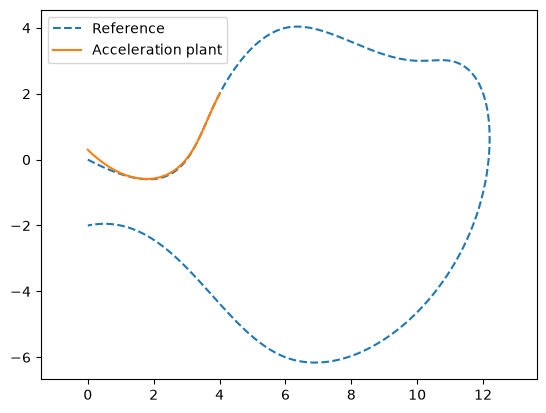

In [16]:
# Short headless closed-loop smoke test; increase cycles for a full track run.
sim = yaml.safe_load((ROOT / "mpc_python/config/simulation.yaml").read_text())
path = compute_path_from_wp(sim["path"]["waypoints_x"], sim["path"]["waypoints_y"], sim["path"]["interpolation_step"])
mujoco.mj_resetData(model, data)
initialize_plant(model, data, ids, sim["start"])
mpc = HolonomicAccelerationMPC(ROOT / "mpc_python/config/mpc_holonomic.yaml")
history = [get_state(data, ids)]
for cycle in range(30):
    state = get_state(data, ids)
    reference = get_holonomic_ref_trajectory(state, path, float(sim["target_speed"]), mpc.control_horizon * mpc.dt, mpc.dt)
    predicted, controls = mpc.solve(state, reference)
    acceleration = mpc.acceleration_command(controls)
    apply_constant_acceleration_command(model, data, ids, acceleration, mpc)
    for _ in range(steps):
        mujoco.mj_step(model, data)
    np.testing.assert_allclose(get_state(data, ids), predicted[:, 1], atol=1e-6)
    history.append(get_state(data, ids))
history = np.array(history)
assert np.isfinite(history).all()
print(f"Passed {len(history)-1} closed-loop intervals; final position {history[-1, :2]}")
plt.plot(path[0], path[1], "--", label="Reference")
plt.plot(history[:, 0], history[:, 1], label="Acceleration plant")
plt.axis("equal")
plt.legend()


For the interactive MuJoCo viewer, run the following optional cell. The standalone entry point is mpc_python/mpc_demo_holonomic_acceleration_mujoco.py. Model acceleration ranges match the default MPC configuration; update both if changing the acceleration limits. This idealized planar plant has no physical obstacle contacts.

In [17]:
# Optional interactive viewer (blocks until the viewer is closed).
from mpc_demo_holonomic_acceleration_mujoco import main
main()
